# RLS: adaptive vs random channel selection

In [4]:
import numpy as np
import matplotlib.pyplot as plt

from wasabi.data_simulation import make_ground_truth_params
from wasabi.utils import make_toeplitz_V, effective_stim_input
from wasabi.rls import (
    RowRLS,
    run_sequential,
    projected_error,
    make_multistep_M,
    truncated_projector,
    run_selection,
    select_stim_from_set,
)

## Ground truth

In [ ]:
# Hyperparameters for the simulation
rng = np.random.default_rng(0)
K, N = 4, 128
w, b = 3.0, -0.5 # width and threshold
BETA_STIM = 5.0
B_SCALE = 5.0  # roughly the std of B_true; keeps B_true at unit scale relative to V

n_stim_ch, n_conditions, n_reps = 8, 10, 10
V = make_toeplitz_V(N, w)
B_true = B_SCALE * rng.standard_normal((K, N))

A_true = np.asarray(make_ground_truth_params(
    K=K, N=N, spectral_radius=0.9, sigma2_Q=0.2, sigma2_C=0.05, w=w, b_input=b,
    B_scale=B_SCALE, seed=0,
)["A"])

# Stim params
BIN_SIZE = 20.0
STIM_DUR = 100.0
n_stim_bins = int(round(STIM_DUR / BIN_SIZE))

# Correlated latent noise, comparable to the smoother covariances in the fit
L = rng.standard_normal((K, K))
R_fixed = L @ L.T + 0.4 * np.eye(K)
chol = np.linalg.cholesky(R_fixed)

# Multi-step propagation over the stim window
M_step = make_multistep_M(A_true, horizon=n_stim_bins)
M_inv = np.linalg.inv(M_step)

## Adaptive vs random selection over a candidate set

In [6]:
print("=" * 60)
print(f"Adaptive(D optimal) vs random selection, contiguous {n_stim_ch}-channel blocks")
print("=" * 60)

# Create candidate set: all contiguous n_stim_ch blocks
cand = np.zeros((N - n_stim_ch + 1, N))
for j in range(N - n_stim_ch + 1):
    cand[j, j:j + n_stim_ch] = 1.0
U_cand = effective_stim_input(cand, V, b, BETA_STIM)

Pu, rank = truncated_projector(U_cand, energy=0.99)
print(f"reachable dimension: {rank} of {N}")

def pred_err_all(W):
    # Error over the full candidate set, which the tracker also trained on
    pred = U_cand @ W.T
    true = U_cand @ B_true.T
    return float(np.linalg.norm(pred - true) / np.linalg.norm(true))

for mode in ("D_opt", "random"):
    errs, logdets, sel_j, tracker = run_selection(
        mode, 1000, cand, U_cand, B_true, chol, R_fixed,
        K, N, seed=1, Pu=Pu, M=M_step, V=V, b=b, BETA_STIM=BETA_STIM,
    )
    print(f"\n  {mode}")
    print(f"    log det Sigma      : {tracker.logdet():.1f}")
    print(f"    pred rel error     : {pred_err_all(tracker.W):.4f}")
    print(f"    projected rel error: {errs[-1]:.4f}")
    print(f"    distinct patterns  : {len(np.unique(sel_j))}")

Adaptive(D optimal) vs random selection, contiguous 8-channel blocks
reachable dimension: 27 of 128


NameError: name 'chol' is not defined

In [ ]:
n_trials, n_seeds = 200, 20
M = make_multistep_M(A_true, horizon=n_stim_bins)

curves, logdet_curves, selections = {}, {}, {}

for mode in ("D_opt", "random"):
    runs, ld_runs, mode_selections = [], [], []

    for seed in range(n_seeds):
        err, logdet, selected_j, RLS_tracker = run_selection(
            mode, n_trials, cand, U_cand, B_true, chol,
            R_fixed, K, N, seed, Pu, M_step, V, b, BETA_STIM
        )
        runs.append(err)
        ld_runs.append(logdet)
        mode_selections.append(selected_j)

    curves[mode] = np.vstack(runs)
    logdet_curves[mode] = np.vstack(ld_runs)
    selections[mode] = np.vstack(mode_selections)

# Validation

D_opt: logdet drop 689.3 nats, final err 0.1169
random: logdet drop 669.8 nats, final err 0.1298


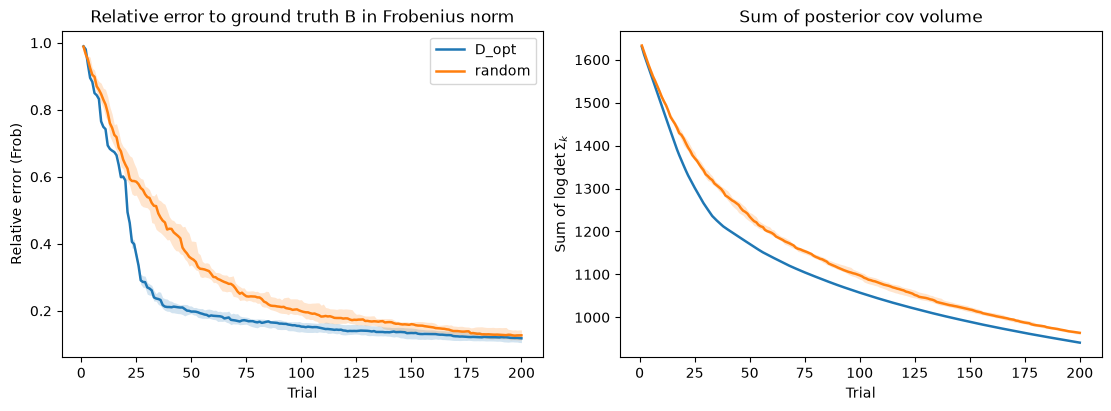

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
trials = np.arange(1, n_trials + 1)

for mode in ("D_opt", "random"):
    ld = logdet_curves[mode]
    print(f"{mode}: logdet drop {ld[:, 0].mean() - ld[:, -1].mean():.1f} nats, "
          f"final err {curves[mode][:, -1].mean():.4f}")
    for ax, data, ylab, logy in (
        (axes[0], curves[mode],        "Relative error (Frob)",             False),
        (axes[1], logdet_curves[mode], r"Sum of $\log\det \Sigma_k$", False),
    ):
        lo, med, hi = np.percentile(data, [25, 50, 75], axis=0)
        line = ax.plot(trials, med, lw=1.8, label=mode)[0]
        ax.fill_between(trials, lo, hi, color=line.get_color(), alpha=0.2, lw=0)
        ax.set_xlabel("Trial")
        ax.set_ylabel(ylab)
        if logy:
            ax.set_yscale("log")

axes[0].legend()
axes[0].set_title("Relative error to ground truth B in Frobenius norm")
axes[1].set_title("Sum of posterior cov volume")
plt.show()

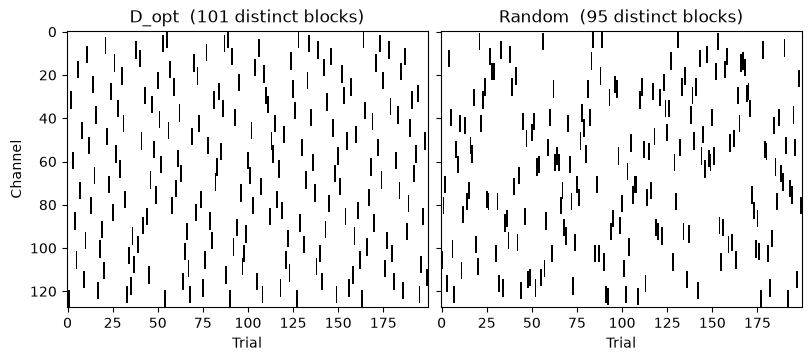

In [ ]:
seed_show = 0

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), constrained_layout=True, sharey=True)

for ax, mode in zip(axes, ("D_opt", "random")):
    js = selections[mode][seed_show]

    S_sel = np.zeros((n_trials, N))
    for trial, j in enumerate(js):
        S_sel[trial, j:j + n_stim_ch] = 1.0

    ax.imshow(S_sel.T, aspect="auto", interpolation="nearest",
              vmin=0, vmax=1, cmap="Greys")
    ax.set_title(f"{mode.capitalize()}  ({len(np.unique(js))} distinct blocks)")
    ax.set_xlabel("Trial")

axes[0].set_ylabel("Channel")
plt.show()

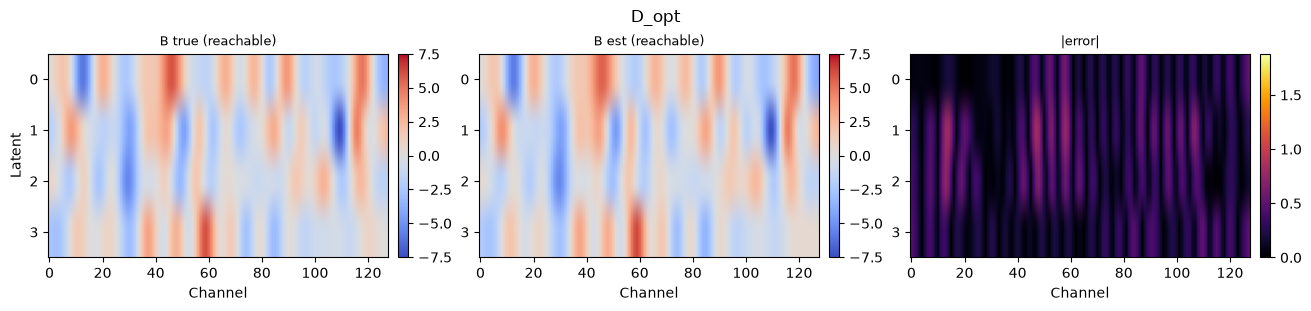

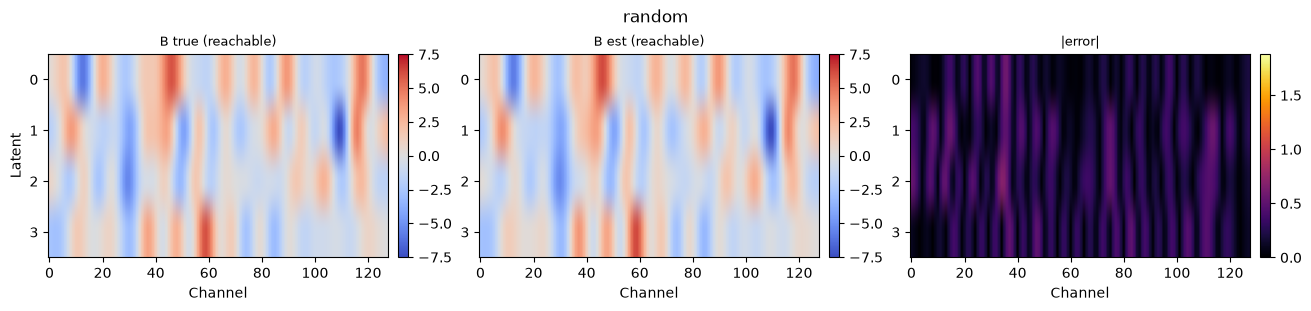

In [ ]:
def compare_B(W, B_ref, Pu, label=""):
    Wp, Bp = W @ Pu, B_ref @ Pu
    fig, axes = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
    lim = np.abs(Bp).max()
    for ax, (data, title, cmap, lo, hi) in zip(axes, [
        (Bp,      "B true (reachable)",  "coolwarm", -lim, lim),
        (Wp,      "B est (reachable)",   "coolwarm", -lim, lim),
        (np.abs(Wp - Bp), "|error|",     "inferno",   0,   lim/4),
    ]):
        im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=lo, vmax=hi)
        ax.set_title(title, fontsize=9)
        ax.set_xlabel("Channel")
        fig.colorbar(im, ax=ax, pad=0.03)
    axes[0].set_ylabel("Latent")
    fig.suptitle(f"{label}")
    plt.show()

for mode in ("D_opt", "random"):
    *_, tracker = run_selection(mode, n_trials, cand, U_cand, B_true, chol,
                                R_fixed, K, N, 0, Pu, M_step, V, b, BETA_STIM)
    compare_B(tracker.W, B_true, Pu, label=mode)

In [ ]:
def run_selection_snap(mode, n_trials, cand, U_cand, B_true, chol, R_fixed,
                       K, N, seed, Pu, M, V, b, BETA_STIM,
                       snap_at=(10, 25, 50, 200), prior_var=25.0,
                       full_noise_cov=True):
    rng_arm = np.random.default_rng(seed)
    tracker = RowRLS(K, N, prior_var=prior_var, full_noise_cov=full_noise_cov)
    M_inv = np.linalg.inv(M)
    R_rls = M_inv @ R_fixed @ M_inv.T
    snaps = {}
    for i in range(n_trials):
        if mode == "D_opt":
            j, _, _ = select_stim_from_set(tracker, cand, V, b, R_rls, BETA_STIM)
        else:
            j = int(rng_arm.integers(0, len(cand)))
        u = U_cand[j]
        z = M @ (B_true @ u) + chol @ rng_arm.standard_normal(K)
        tracker.update(u, M_inv @ z, R_rls)
        if (i + 1) in snap_at:
            snaps[i + 1] = tracker.W.copy()
    return snaps

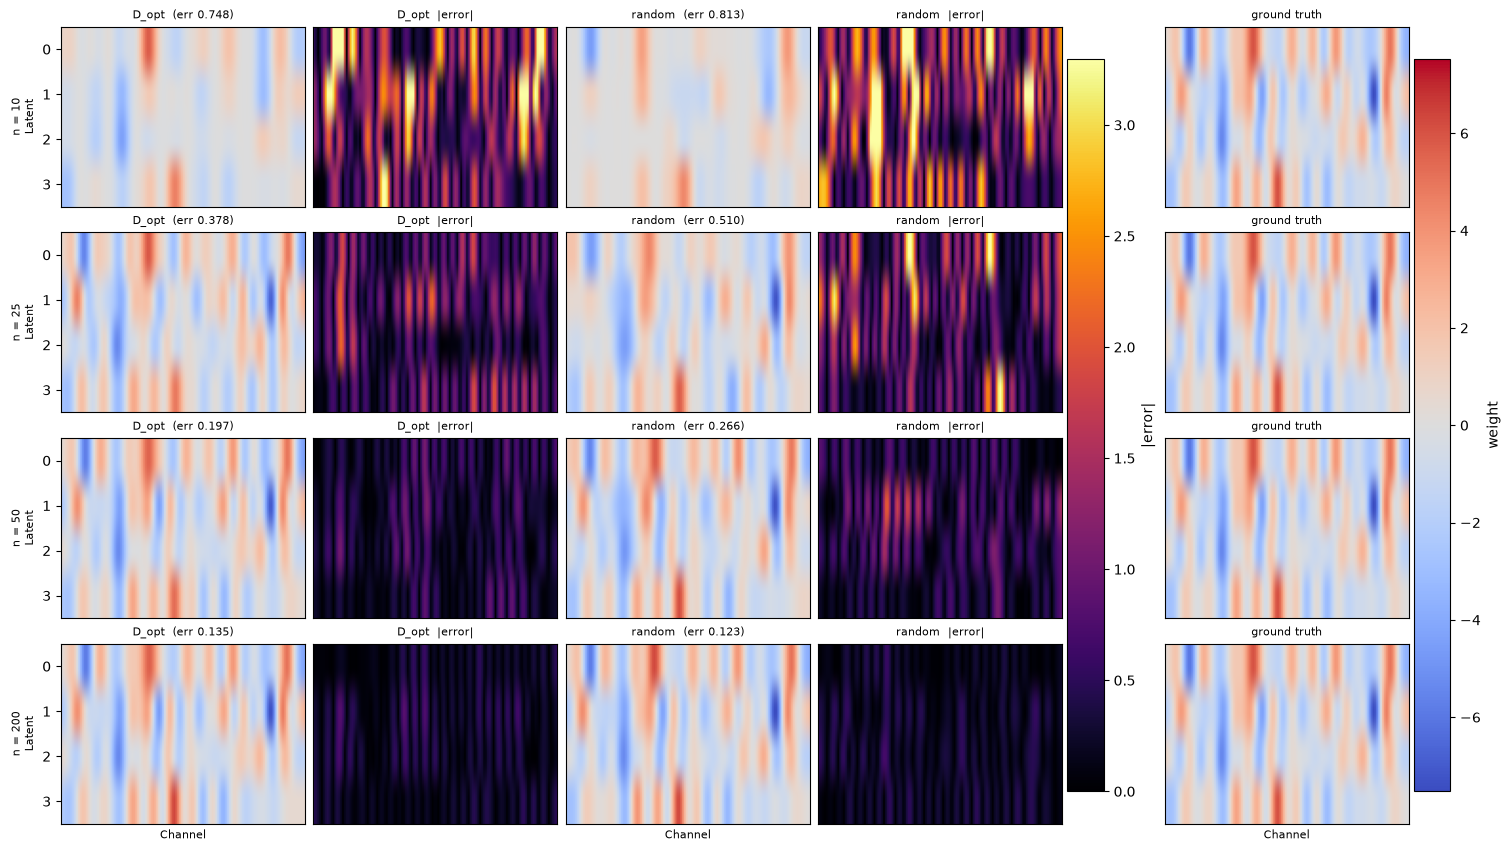

In [ ]:
snap_at = (10, 25, 50, 200)
modes = ("D_opt", "random")
snaps = {m: run_selection_snap(m, 200, cand, U_cand, B_true, chol, R_fixed,
                               K, N, 0, Pu, M_step, V, b, BETA_STIM, snap_at)
         for m in modes}

Bp = B_true @ Pu
lim = np.abs(Bp).max()
# Fix the error scale at the earliest snapshot so shrinkage across rows is visible
err_lim = max(np.abs(snaps[m][snap_at[0]] @ Pu - Bp).max()/2 for m in modes)

cols = [("D_opt", "W"), ("D_opt", "err"), ("random", "W"), ("random", "err"), (None, "gt")]
fig, axes = plt.subplots(len(snap_at), len(cols),
                         figsize=(3.0 * len(cols), 2.1 * len(snap_at)),
                         constrained_layout=True)
for r, n in enumerate(snap_at):
    for c, (mode, kind) in enumerate(cols):
        ax = axes[r, c]
        if kind == "gt":
            im_w = ax.imshow(Bp, aspect="auto", cmap="coolwarm", vmin=-lim, vmax=lim)
            title = "ground truth"
        else:
            Wp = snaps[mode][n] @ Pu
            if kind == "W":
                im_w = ax.imshow(Wp, aspect="auto", cmap="coolwarm", vmin=-lim, vmax=lim)
                rel = np.linalg.norm(Wp - Bp) / np.linalg.norm(Bp)
                title = f"{mode}  (frob err {rel:.3f})"
            else:
                im_e = ax.imshow(np.abs(Wp - Bp), aspect="auto", cmap="inferno",
                                 vmin=0, vmax=err_lim)
                title = f"{mode}  |error|"
        ax.set_title(title, fontsize=8)
        ax.set_xticks([])
        if c > 0:
            ax.set_yticks([])
    axes[r, 0].set_ylabel(f"n = {n}\nLatent", fontsize=8)

for c in (0, 2, 4):
    axes[-1, c].set_xlabel("Channel", fontsize=8)
fig.colorbar(im_w, ax=axes[:, 4], pad=0.02, label="weight")
fig.colorbar(im_e, ax=axes[:, 3], pad=0.02, label="|error|")
plt.show()

In [ ]:
# # Posterior calibration on the probed subspace
# RLS_tracker = RowRLS(K, N, prior_var=25.0)
# run_sequential(RLS_tracker, U, Z, R)
# zs = []
# for k in range(K):
#     for u in U[::7]:
#         var = u @ RLS_tracker.Sigma[k] @ u
#         zs.append(((RLS_tracker.W[k] - B_true[k]) @ u) / np.sqrt(max(var, 1e-12)))
# zs = np.array(zs)
# print(f"Calibration z-scores: mean {zs.mean():+.3f}, std {zs.std():.3f} (target 0, 1)")
# print("\n" + "=" * 60)
# print("Greedy channel selection from a cold prior")
# print("=" * 60)
# RLS_tracker = RowRLS(K, N, prior_var=25.0)
# s_sel, chosen, gain = select_stim_greedy(RLS_tracker, V, b, R_fixed, n_stim_ch, BETA_STIM)
# print(f"  channels: {sorted(chosen)}")
# print(f"  info gain: {gain:.3f} nats")
# print(f"  (compare best contiguous block: "
#         f"{max(RLS_tracker.info_gain(u, R_fixed) for u in U_cand):.3f} nats)")

# Q_fit = 0.2 * np.eye(state_dim)  # match dynamics_covariance to initialization
# U_real = effective_stim_input(np.asarray(S[:, t_stim, :]), np.asarray(params_GT["V"]), float(b_fit), BETA_STIM)

# # Get perturbation term from EKF/RTS smoother outputs
# Z_real, R_real = get_perturbation_agg(posts_fit.smoothed_means, posts_fit.smoothed_covariances, A_fit, Q_fit, t_stim - 1, t_stim)

# B_true_gt = np.asarray(params_GT["B"])  # ground truth in the original latent basis
# B_target = M_inv @ B_true_gt   # ground truth expressed in the fitted latent basis
# prior_var = float((B_target ** 2).mean())

# RLS_tracker = RowRLS(K, N, prior_var=prior_var)
# nis_real, logdet_real = run_sequential(RLS_tracker, U_real, Z_real, R_real)
# print(f"NIS {nis_real.mean():.2f} (target {K}), proj err "
#       f"{projected_error(RLS_tracker.W, B_target, U_real):.4f}")